# Multiwavelength-Astronomie: Bilder von Galaxien und Nebeln

Das Notebook fragt Datenbanken nach einer Galaxie oder einem Nebel und macht daraus Bilder: SIMBAD liefert Typ, Lage, Größe und Entfernung, NASA SkyView die Aufnahmen vom Röntgen- bis zum Radiobereich. Der Code steht in [`code/`](https://github.com/deltorobarba/science/tree/main/code) (`catalog.py` für SIMBAD, `surveys.py` für SkyView, `plotting.py` für die Bilder); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

In [1]:
import sys
import urllib.request
from pathlib import Path

CODE = Path.cwd() / "code"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir()
    for f in ["catalog.py", "surveys.py", "plotting.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner "code" direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import catalog, surveys, plotting
CACHE = Path.cwd() / "data" / "images"                 # Downloads, ein Unterordner pro Objekt

**1. Galaxien und Nebel im Messier-Katalog**

SIMBAD, die Objektdatenbank des CDS in Straßburg (bei einem Ausfall ihr Spiegel an der CfA in Harvard), wird nach allen 110 Objekten des Messier-Katalogs gefragt. Charles Messier hat im 18. Jahrhundert die hellsten verwaschenen Flecken des Nordhimmels gesammelt, damit man sie nicht mit Kometen verwechselt; deshalb ist sein Katalog eine handliche Auswahl an Galaxien und Nebeln, die in jeder Durchmusterung gut zu sehen sind.

Die Liste nennt 40 Galaxien und 12 Nebel mit SIMBAD-Typ und Größe; vier große Nebel (M 8, 16, 17, 20) führt SIMBAD unter dem Sternhaufen in ihrer Mitte, der Code trägt sie von Hand als Nebel ein. Die Karte zeigt den Himmel in galaktischen Koordinaten mit der Ebene der Milchstraße als Mittellinie: Die meisten Nebel liegen in dieser Ebene, die Galaxien weit davon entfernt, weil der Staub der Milchstraße den Blick nach draußen verdeckt (Zone of Avoidance). Die Häufung oben rechts ist der Virgo-Haufen, unten links liegen M 31 und M 33; planetarische Nebel wie M 57 und M 97 liegen auch abseits der Ebene, weil sie aus alten Sternen entstehen, die weiter über der Scheibe verteilt sind.

110 Messier-Objekte: 56 Sternhaufen, 40 Galaxien, 12 Nebel, 2 sonstige
In Klammern der SIMBAD-Typ und die Größe (große Achse in Bogenminuten).

Galaxien (40):
  M 31 (AGN, 200′), M 32 (GiG, 3′), M 33 (GiG, 60′), M 49 (Sy2, 8′), M 51 (Sy2, 9′), M 58 (Sy2, 6′), M 59
  (GiG, 6′), M 60 (GiC, 6′), M 61 (Sy2, 5′), M 63 (LIN, 13′), M 64 (SyG, 11′), M 65 (GiP, 16′), M 66 (AGN,
  11′), M 74 (G, 7′), M 77 (Sy2, 5′), M 81 (Sy2, 21′), M 82 (AGN), M 83 (SBG, 14′), M 84 (Sy2, 6′), M 85 (GiP,
  7′), M 86 (GiG, 9′), M 87 (AGN, 6′), M 88 (Sy2, 7′), M 89 (Sy2, 4′), M 90 (Sy2, 10′), M 91 (LIN, 5′), M 94
  (SyG, 7′), M 95 (GiP, 6′), M 96 (GiP, 7′), M 98 (LIN, 11′), M 99 (H2G, 5′), M 100 (AGN, 6′), M 101 (GiP,
  22′), M 102 (SyG, 6′), M 104 (LIN, 9′), M 105 (LIN, 5′), M 106 (Sy2, 18′), M 108 (AGN, 15′), M 109 (GiG,
  8′), M 110 (GiG, 3′)

Nebel (12):
  M 1 (SNR, 7′), M 8 (OpC, 90′), M 16 (OpC, 35′), M 17 (OpC, 11′), M 20 (OpC, 28′), M 27 (PN, 7′), M 42 (HII,
  66′), M 43 (HII), M 57 (PN, 1′), M 76 (PN, 2′)

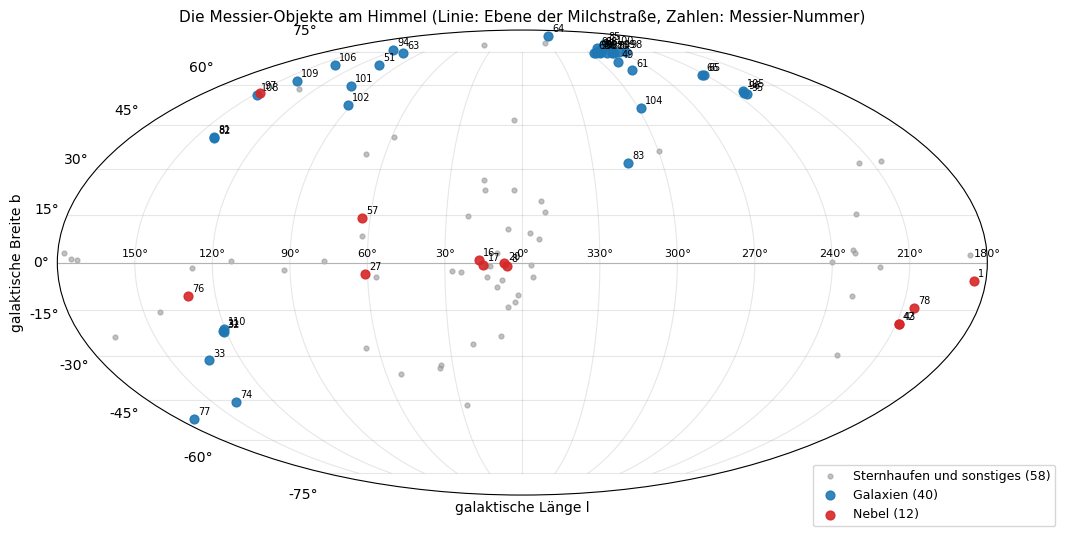

In [2]:
messier = catalog.messier(CACHE)
catalog.show_messier(messier)
plotting.sky_map(messier)

**2. Das gewählte Objekt**

`TARGET` nimmt jeden Namen, den SIMBAD kennt (`"M 51"`, `"NGC 891"`, `"Orion Nebula"`, `"Helix Nebula"`). SIMBAD liefert Typ, Koordinaten, die Größe aus Katalogen und alle veröffentlichten Entfernungen; der Median der Entfernungen, die nicht aus der Rotverschiebung stammen, gibt den Maßstab der Bilder in Lichtjahren. Das Bildfeld ist 1.6-mal so groß wie das Objekt, damit Rand und Nachbarn mit draufkommen, höchstens aber 3°.

Für M 51, die Whirlpool-Galaxie, steht hier eine Spiralgalaxie mit aktivem Kern (Seyfert 2), 9.0′ × 7.8′ groß und 7.8 Mpc oder 26 Millionen Lichtjahre entfernt; eine Bogenminute sind dort rund 7 400 Lichtjahre. Kennt SIMBAD keine Größe (bei vielen Nebeln), setzt der Code 15′ ein und sagt das; `FOV_ARCMIN` legt das Feld dann von Hand fest.

In [3]:
TARGET = "M 51"        # jeder Name, den SIMBAD kennt: "M 42", "M 1", "M 57", "M 81", "M 104", "NGC 891", "Helix Nebula"
FOV_ARCMIN = None      # Bildfeld in Bogenminuten; None = 1.6-mal die Größe laut SIMBAD, höchstens 3°
PIXELS = 600

target = catalog.lookup(TARGET, CACHE)
fov = FOV_ARCMIN or min(1.6 * target.size, surveys.MAX_FOV)
catalog.describe(target, fov, PIXELS)

M 51
Typ:          Galaxie, Seyfert 2 Galaxy (Sy2)
Koordinaten:  13h29m53s +47d11m43s  (RA 202.4696°, Dec +47.1953°)
Größe:        9.0′ × 7.8′, PA 28°  (laut SIMBAD)
Helligkeit:   V = 8.36
Entfernung:   7.8 Mpc = 26 Millionen Lichtjahre  (Median aus 6 Messungen ohne Rotverschiebung)
Maßstab:      1′ = 7 448 Lichtjahre; große Achse 67 355 Lichtjahre
Bildfeld:     14.5′ × 14.5′ mit 600 × 600 Pixeln (1.4″ pro Pixel)


**3. Farbbilder**

Ein Farbbild entsteht, wenn man drei Bänder als Rot, Grün und Blau übereinanderlegt, das langwelligste als Rot. SkyView (NASA) schneidet jedes Band aus seiner Durchmusterung aus und rechnet es auf dasselbe Pixelgitter, deshalb passen die Bänder ohne weitere Ausrichtung aufeinander; jedes wird für sich mit einer Asinh-Kurve gestreckt, damit schwache Außenbereiche und der helle Kern zugleich sichtbar sind. Die vier Mischungen: optisch wie mit dem Auge (DSS2 rot und blau, Grün als ihr Mittel), nahes Infrarot (2MASS), mittleres Infrarot (WISE) und eine Falschfarbenmischung aus warmem Staub (WISE 12 µm), alten Sternen (WISE 3.4 µm) und jungen Sternen (GALEX-UV).

Bei M 51 zeigt das optische Bild blaue Spiralarme mit hellen Sternhaufen und dunklen Staubbändern; im nahen Infrarot sind Staub und Blau verschwunden, und es bleiben die alten Sterne, die Kern und Begleiter NGC 5195 am hellsten machen. Im mittleren Infrarot leuchten die Arme rot vom warmen Staub, in der Falschfarbenmischung liegen junge Sterne (blau) und Staub (rot) gemeinsam in den Armen, während der Begleiter grün bis gelb ist, weil dort alte Sterne überwiegen. Gestrichelt ist die Größe laut SIMBAD, der Balken unten rechts der Maßstab; fehlt ein Band (für M 42 hat SkyView zum Beispiel keine GALEX-Daten), entfällt das Bild.

10 Bilder, 14.5′ mit 600 Pixeln


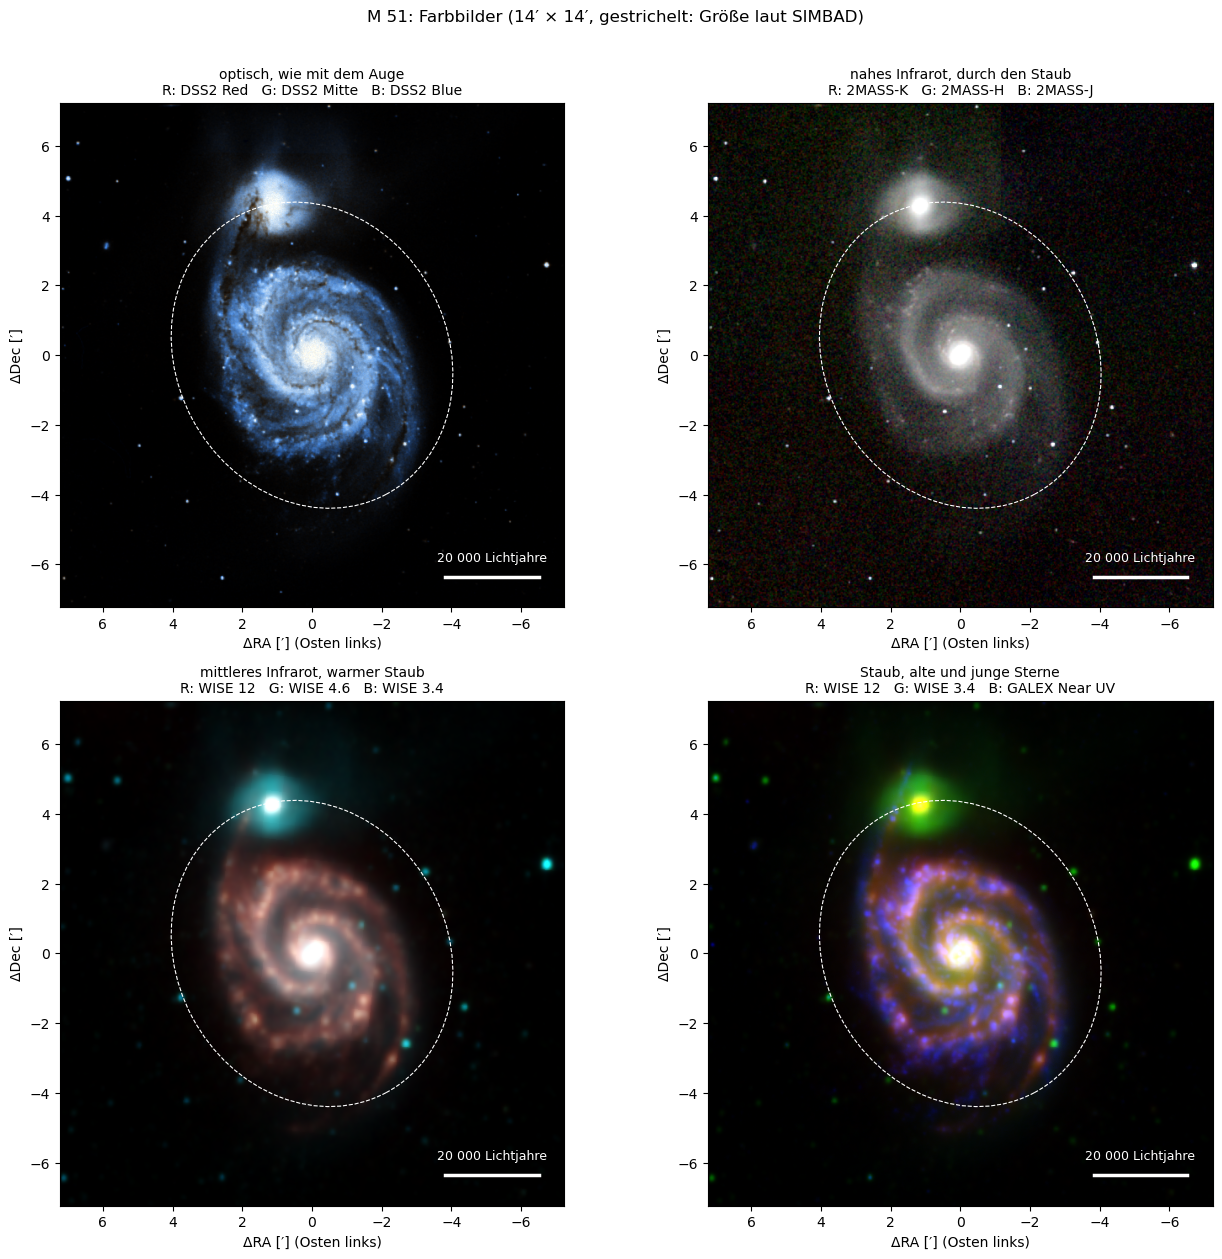

In [4]:
COMPOSITES = {"optisch, wie mit dem Auge":         ["DSS2 Red", "DSS2 Mitte", "DSS2 Blue"],
              "nahes Infrarot, durch den Staub":   ["2MASS-K", "2MASS-H", "2MASS-J"],
              "mittleres Infrarot, warmer Staub":  ["WISE 12", "WISE 4.6", "WISE 3.4"],
              "Staub, alte und junge Sterne":      ["WISE 12", "WISE 3.4", "GALEX Near UV"]}
STRETCHES = {"optisch, wie mit dem Auge": dict(lo=5, hi=99.95, soft=1.0, gamma=1.6)}   # sonst lo=20

bands = sorted({b for channels in COMPOSITES.values() for b in channels})
images = surveys.images(target, bands, fov, PIXELS, CACHE)
plotting.color_images(target, images, COMPOSITES, fov, STRETCHES)

**4. Sechs Bänder vom Ultravioletten zum mittleren Infrarot**

Dieselben Daten einzeln, jedes Band mit eigener Farbskala und nach Wellenlänge sortiert, von 0.23 µm bis 12 µm. Jedes Band zeigt eine andere Zutat: das UV die jungen, heißen Sterne, das Optische das Licht aller Sterne mit dem Staub davor, 2.2 und 3.4 µm die alten Sterne, die den größten Teil der Sternmasse tragen, 12 µm den Staub, den junge Sterne aufheizen. Über jedem Bild stehen Band, Wellenlänge, was man vor allem sieht, und die Auflösung.

Bei M 51 zerfallen die Arme im UV in einzelne Knoten, die Gebiete, in denen gerade Sterne entstehen, und der Begleiter NGC 5195 ist dort kaum zu sehen, weil er fast keine Sterne mehr bildet. Bei 2.2 und 3.4 µm sind Kern und Begleiter am hellsten und die Arme glatt; bei 12 µm kehren die Knoten der Arme zurück, weil dort die jungen Sterne den Staub heizen.

6 Bilder, 14.5′ mit 600 Pixeln


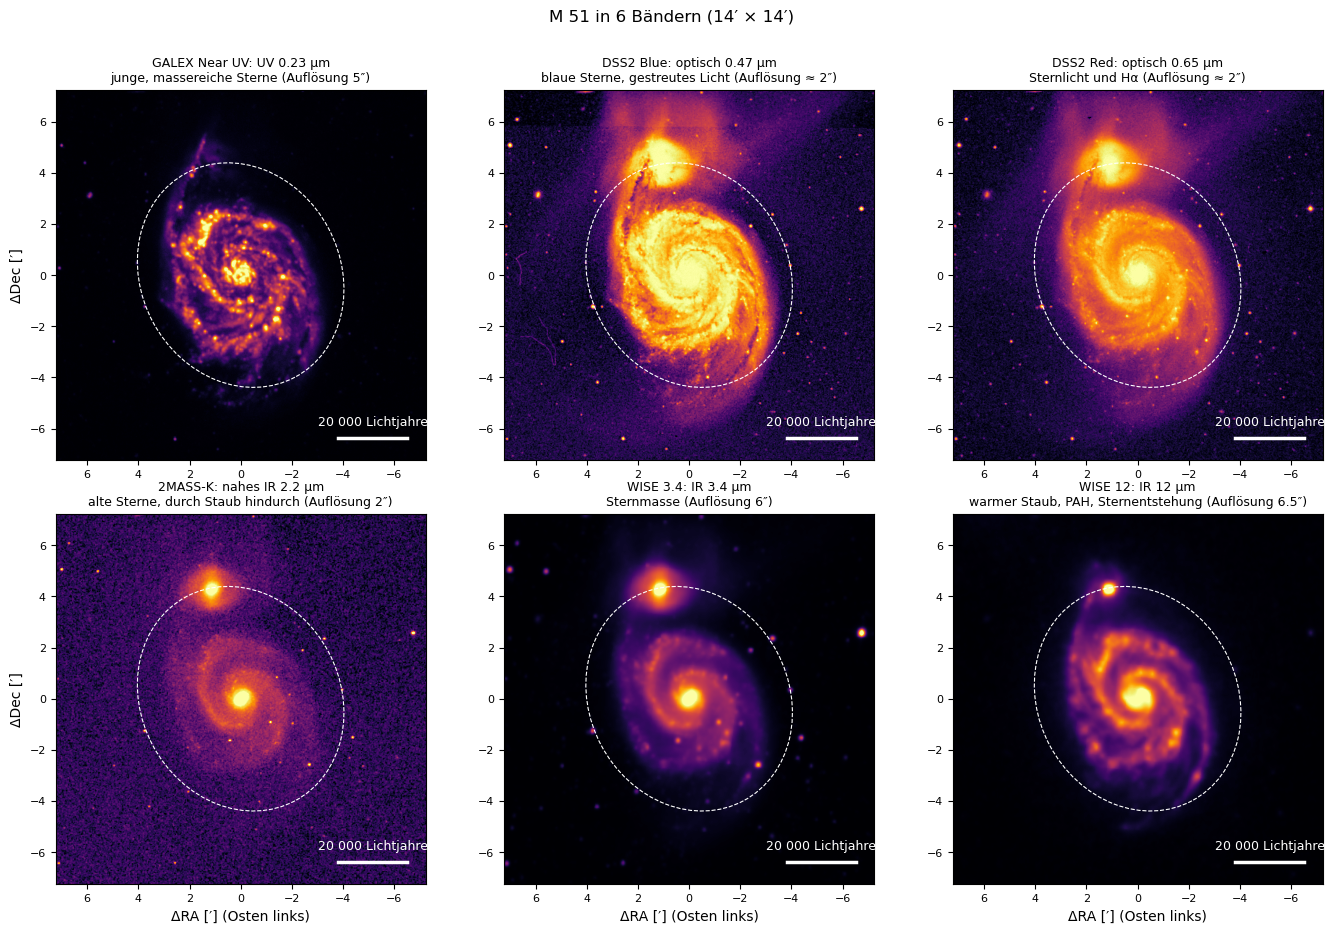

In [5]:
BANDS = ["GALEX Near UV", "DSS2 Blue", "DSS2 Red", "2MASS-K", "WISE 3.4", "WISE 12"]

images = surveys.images(target, BANDS, fov, PIXELS, CACHE)     # meist schon im Cache aus Schritt 3
plotting.band_grid(target, images, fov)

**5. Vom Röntgen- bis zum Radiobereich**

Neun Durchmusterungen vom Röntgenbereich (ROSAT) bis 21 cm (NVSS) in einem Feld von mindestens 1° und höchstens 3°. Viele dieser Karten lösen nur Bogenminuten auf (Hα 6′, IRIS 4′, Planck bei 30 GHz 32′), ein kleines Objekt wäre im engen Feld nur ein Fleck; das größere Feld zeigt dafür die Umgebung. Die Hα-Karte ist aus mehreren Durchmusterungen der Milchstraße zusammengesetzt.

M 51 ist im Röntgenbereich, bei 100 µm, 350 µm und 21 cm ein Fleck in der Mitte, bei 22 µm und im Optischen noch eine Spirale. In der Hα-Karte und bei 30 GHz fehlt die Galaxie: Die Hα-Karte zeigt nur das schwache Leuchten der Milchstraße im Vordergrund, und bei 32′ Auflösung gehen schwache Quellen im Rauschen und in den Schwankungen der Hintergrundstrahlung unter. Die Punkte im NVSS-Bild sind ferne Radioquellen, meist aktive Galaxienkerne. Bei einem Nebel wie M 42 ist es umgekehrt: Er leuchtet in fast allen Bändern, und bei 100 und 350 µm erscheinen die Staubfilamente seiner Molekülwolke (der waagrechte Streifen durch M 42 in der Hα-Karte ist vermutlich ein Überlauf des übersättigten Detektors).

9 Bilder, 60.0′ mit 360 Pixeln


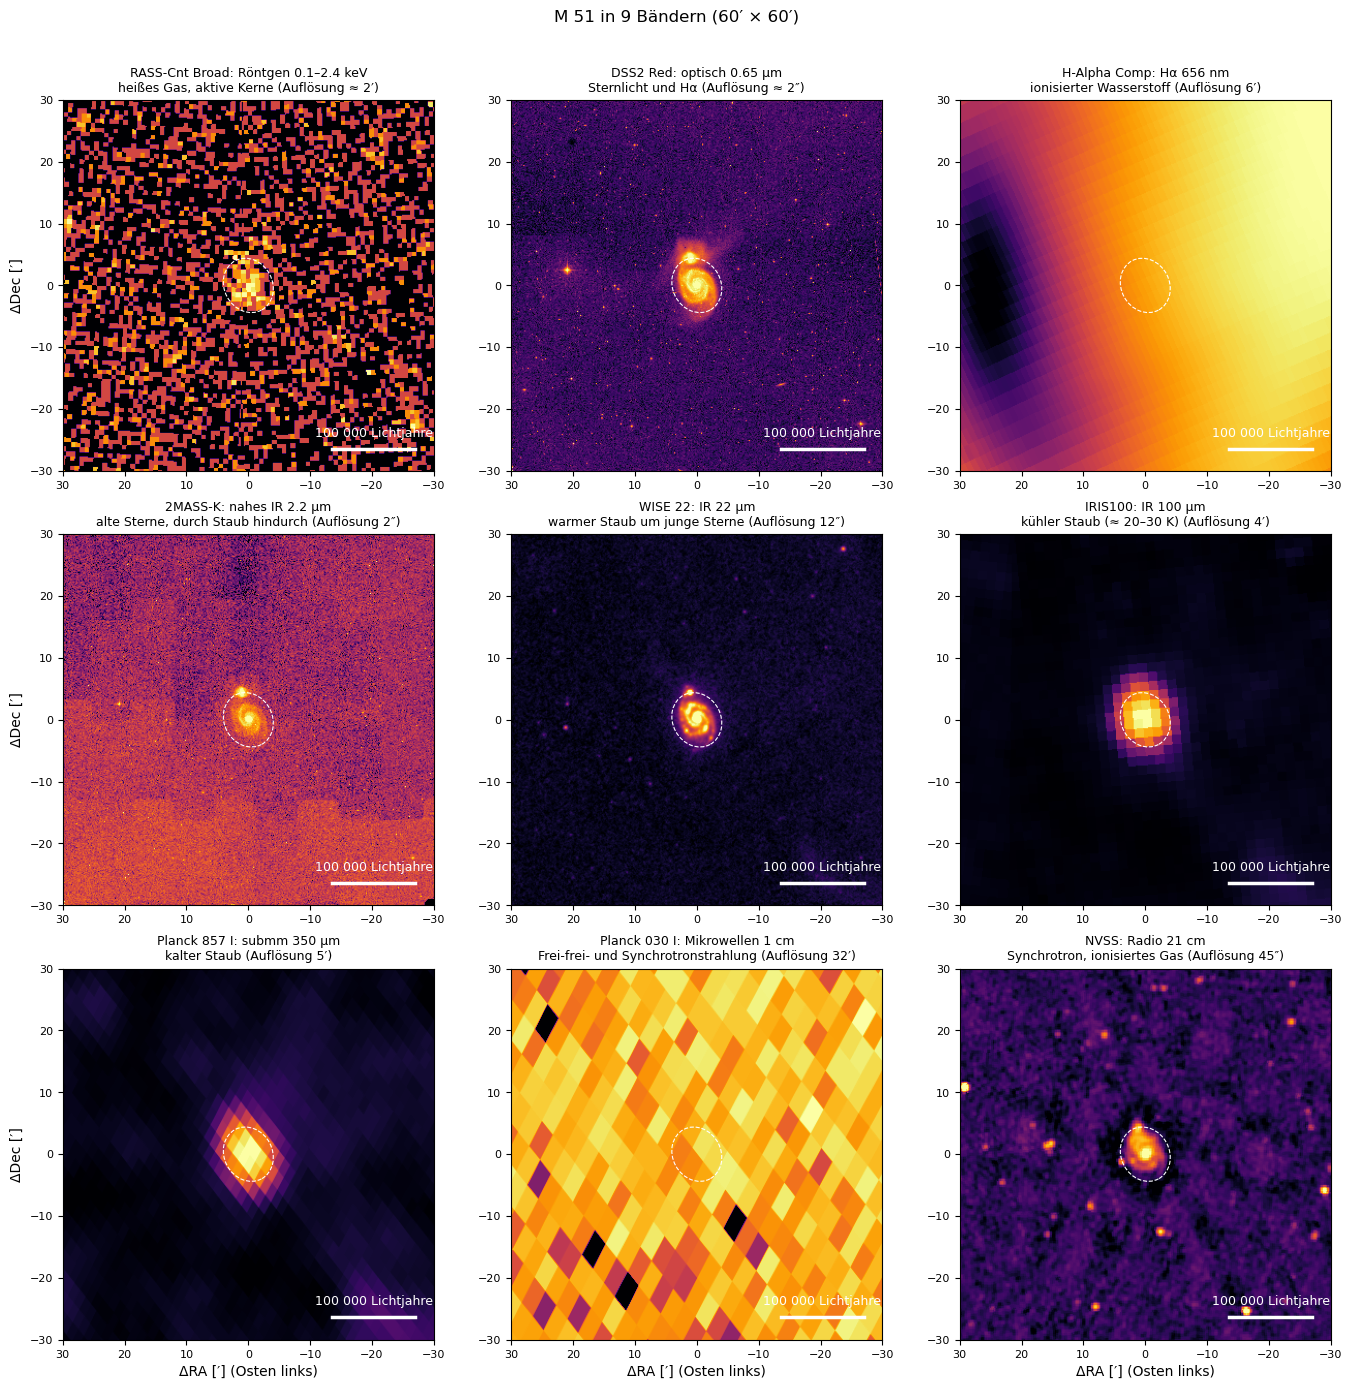

In [6]:
WIDE_BANDS = ["RASS-Cnt Broad", "DSS2 Red", "H-Alpha Comp", "2MASS-K", "WISE 22",
              "IRIS100", "Planck 857 I", "Planck 030 I", "NVSS"]
wide = min(max(60, 3 * target.size), surveys.MAX_FOV)     # mindestens 1°: viele dieser Karten lösen nur Bogenminuten auf

wide_images = surveys.images(target, WIDE_BANDS, wide, 360, CACHE)
plotting.band_grid(target, wide_images, wide, lo=1, hi=99.9, soft=0.05)